# 04 Markov model and reactive-flux pathways

Six-state VAMPnet assignments $\to$ reversible MSM at a 5 ns lag (50 frames) $\to$ committors, MFPTs
and transition-path-theory pathways, all from the maximum-likelihood transition matrix.

Source = kinetic state with the largest Melted content, sink = largest Pure Native content
($\nu$: s5 $\to$ s2, S: s1 $\to$ s5).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from deeptime.markov import TransitionCountEstimator
from deeptime.markov.msm import MaximumLikelihoodMSM, MarkovStateModel
from deeptime.markov.tools.analysis import mfpt

import abeta_tips as T

FOLDS = ["nu_8EZD", "S_7Q4M"]
LAG = 50                     # frames = 5 ns
dtrajs = {f: T.load_dtrajs(f) for f in FOLDS}

## Implied timescales and Chapman-Kolmogorov test

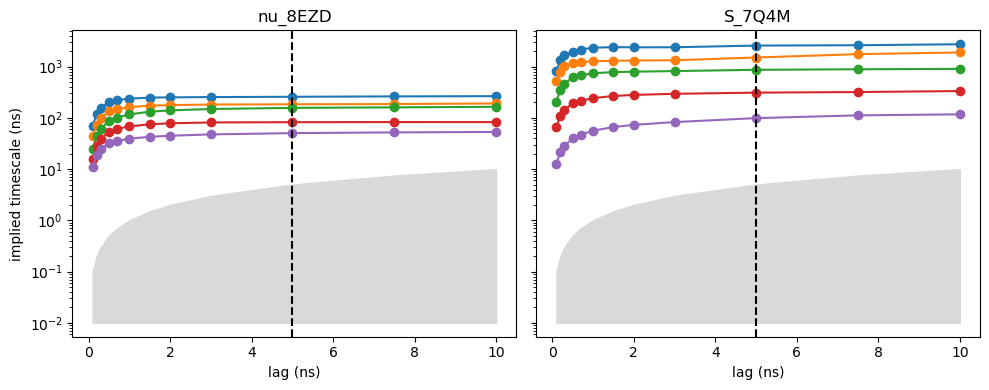

In [2]:
def mle(dt, lag, mode="sliding"):
    c = TransitionCountEstimator(lagtime=lag, count_mode=mode).fit_fetch(dt).submodel_largest()
    return MaximumLikelihoodMSM(reversible=True).fit_fetch(c)

lags = [1, 2, 3, 5, 7, 10, 15, 20, 30, 50, 75, 100]
fig, axs = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, f in zip(axs, FOLDS):
    its = np.array([mle(dtrajs[f], l).timescales()[:5] * T.DT_NS for l in lags])
    ax.semilogy(np.array(lags) * T.DT_NS, its, "o-")
    ax.fill_between(np.array(lags) * T.DT_NS, 1e-2, np.array(lags) * T.DT_NS, color="0.85")
    ax.axvline(LAG * T.DT_NS, ls="--", c="k")
    ax.set_title(f); ax.set_xlabel("lag (ns)")
axs[0].set_ylabel("implied timescale (ns)")
plt.tight_layout()

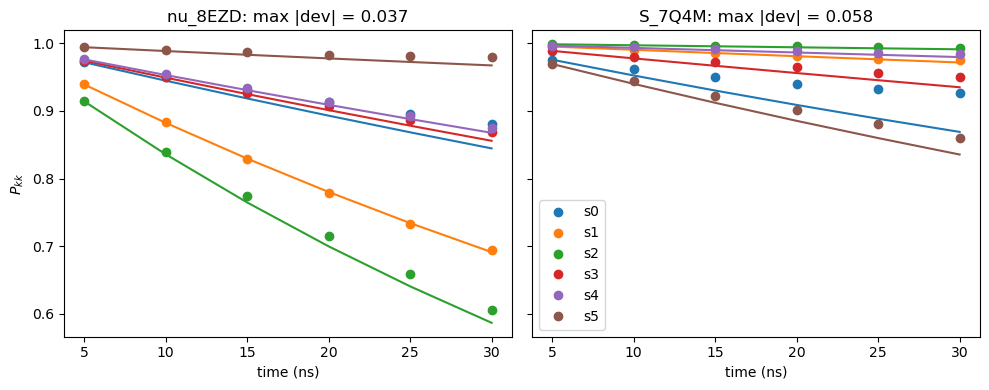

In [3]:
def ck_test(dt, lag, mlags=6):
    models = [mle(dt, m * lag) for m in range(1, mlags + 1)]
    T1 = models[0].transition_matrix
    pred = np.array([np.diag(np.linalg.matrix_power(T1, m)) for m in range(1, mlags + 1)])
    est = np.array([np.diag(M.transition_matrix) for M in models])
    return pred, est

fig, axs = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, f in zip(axs, FOLDS):
    pred, est = ck_test(dtrajs[f], LAG)
    t = np.arange(1, 7) * LAG * T.DT_NS
    for k in range(6):
        ax.plot(t, pred[:, k], c=f"C{k}")
        ax.plot(t, est[:, k], "o", c=f"C{k}", label=f"s{k}")
    ax.set_title(f"{f}: max |dev| = {np.abs(pred - est).max():.3f}"); ax.set_xlabel("time (ns)")
axs[0].set_ylabel("$P_{kk}$"); axs[1].legend()
plt.tight_layout()

## Working MSM

In [4]:
msm, counts = {}, {}
for f in FOLDS:
    counts[f] = TransitionCountEstimator(lagtime=LAG, count_mode="effective").fit_fetch(dtrajs[f])
    msm[f] = MaximumLikelihoodMSM(reversible=True).fit_fetch(counts[f])
    assert msm[f].n_states == 6

def mfpt_ns(P):
    """row = from, column = to"""
    return np.array([mfpt(P, target=j, tau=LAG) for j in range(len(P))]).T * T.DT_NS

for f in FOLDS:
    print(f, "transition matrix (%), tau = 5 ns")
    print(pd.DataFrame(100 * msm[f].transition_matrix).round(2), "\n")

nu_8EZD transition matrix (%), tau = 5 ns
       0      1      2      3      4      5
0  97.19   0.27   0.04   0.02   0.02   2.47
1   2.32  93.91   0.86   0.23   2.50   0.17
2   1.39   3.94  91.41   0.04   3.15   0.08
3   0.02   0.04   0.00  97.42   0.60   1.91
4   0.03   0.38   0.11   0.51  97.62   1.36
5   0.30   0.00   0.00   0.15   0.13  99.42 

S_7Q4M transition matrix (%), tau = 5 ns
       0      1      2      3      4      5
0  97.57   0.00   0.00   0.56   0.05   1.83
1   0.00  99.51   0.07   0.42   0.00   0.00
2   0.00   0.09  99.85   0.04   0.02   0.00
3   0.26   0.65   0.05  98.87   0.01   0.16
4   0.10   0.00   0.09   0.05  99.66   0.10
5   2.53   0.00   0.00   0.47   0.07  96.93 



## Transition-path theory

In [5]:
def tpt(P, src, snk, fraction=0.99):
    fl = MarkovStateModel(P).reactive_flux([src], [snk])
    paths, pf = fl.pathways(fraction=fraction)
    names = ["->".join(f"s{int(s)}" for s in p) for p in paths]
    share = 100 * np.asarray(pf) / np.sum(pf)
    return fl, dict(zip(names, share)), 100 * np.sum(pf) / fl.total_flux

res = {}
for f in FOLDS:
    src, snk = T.FOLDS[f]["source"], T.FOLDS[f]["sink"]
    P = msm[f].transition_matrix
    fl, shares, covered = tpt(P, src, snk)
    raw = np.bincount(np.concatenate(dtrajs[f]), minlength=6) / sum(len(t) for t in dtrajs[f])
    through = [sum(v for p, v in shares.items() if f"s{k}" in p.split("->")) for k in range(6)]
    res[f] = dict(P=P, fl=fl, shares=shares)

    print(f"==== {f}: source s{src} -> sink s{snk}")
    print(pd.DataFrame({"raw %": 100 * raw, "pi %": 100 * msm[f].stationary_distribution,
                        "residence (ns)": LAG * T.DT_NS / (1 - np.diag(P)),
                        "q+": fl.forward_committor, "flux share %": through},
                       index=[f"s{k}" for k in range(6)]).round(3))
    print(f"\n{len(shares)} pathways, {covered:.1f}% of the total reactive flux")
    print("pathways for 95% of the flux:", len(fl.pathways(fraction=0.95)[0]))
    for p, v in shares.items():
        print(f"  {v:5.1f}%  {p}")
    first = {}
    for p, v in shares.items():
        hop = "->".join(p.split("->")[:2])
        first[hop] = first.get(hop, 0) + v
    print("first committed step:", {k: round(v, 1) for k, v in first.items()})
    print()

==== nu_8EZD: source s5 -> sink s2
     raw %    pi %  residence (ns)     q+  flux share %
s0  11.410   9.282         177.840  0.031        39.992
s1  10.788   1.079          82.123  0.187        42.250
s2  22.172   0.237          58.240  1.000       100.000
s3  10.583   6.109         194.044  0.022        14.019
s4  18.475   7.096         209.679  0.079        54.733
s5  26.572  76.198         857.190  0.000       100.000

8 pathways, 99.0% of the total reactive flux
pathways for 95% of the flux: 6
   38.8%  s5->s4->s2
   22.0%  s5->s0->s1->s2
   17.9%  s5->s0->s2
   11.7%  s5->s3->s4->s1->s2
    4.2%  s5->s4->s1->s2
    2.3%  s5->s3->s1->s2
    2.0%  s5->s1->s2
    1.0%  s5->s2
first committed step: {'s5->s4': 43.0, 's5->s0': 40.0, 's5->s3': 14.0, 's5->s1': 2.0, 's5->s2': 1.0}

==== S_7Q4M: source s1 -> sink s5
     raw %    pi %  residence (ns)     q+  flux share %
s0   9.085   9.821         205.406  0.844        54.134
s1  22.123  32.670        1028.292  0.000       100.000
s2  11.

## MFPT matrices (ns, row = from)

In [6]:
for f in FOLDS:
    print(f)
    print(pd.DataFrame(mfpt_ns(res[f]["P"]), index=[f"s{k}" for k in range(6)],
                       columns=[f"s{k}" for k in range(6)]).round(0), "\n")

nu_8EZD
        s0      s1       s2      s3      s4     s5
s0     0.0  8378.0  26923.0  3233.0  3172.0  223.0
s1  1182.0     0.0  22723.0  2880.0  1676.0  379.0
s2  1326.0  4322.0      0.0  2882.0  1378.0  398.0
s3  1994.0  8837.0  27240.0     0.0  2620.0  284.0
s4  1912.0  7612.0  25715.0  2599.0     0.0  351.0
s5  1802.0  9153.0  27573.0  3101.0  3190.0    0.0 

S_7Q4M
        s0      s1       s2      s3       s4      s5
s0     0.0  2891.0  11423.0  1192.0  27876.0  1483.0
s1  6204.0     0.0  10263.0  1663.0  30905.0  6732.0
s2  8885.0  4411.0      0.0  4714.0  30200.0  9389.0
s3  4603.0  1761.0  10664.0     0.0  29860.0  5136.0
s4  4849.0  4565.0   9712.0  3422.0      0.0  5199.0
s5   981.0  2918.0  11426.0  1223.0  27725.0     0.0 

